# Klasifikasi Penggunaan dan Tutupan Lahan Jawa Timur

Notebook ini menyusun alur klasifikasi tutupan lahan menggunakan citra Sentinel-2A. Tahapannya meliputi pemahaman data, pengumpulan sampel, ekstraksi band dan indeks spektral, eksplorasi data, pelatihan serta evaluasi model, pembuatan peta hasil klasifikasi, dan penarikan kesimpulan.


## 1. Data Understanding

### 1.1 Latar Belakang

Informasi tutupan lahan dapat digunakan untuk mendukung perencanaan wilayah, pemantauan lahan pertanian, dan pengamatan ekosistem. Citra satelit memungkinkan karakteristik permukaan diamati pada area yang luas secara konsisten.

Pada proyek ini, citra Sentinel-2A digunakan untuk membangun model yang membedakan enam kelas tutupan lahan di Jawa Timur. Hasilnya ditampilkan sebagai peta tematik dan ringkasan informasi. Klasifikasi merupakan hasil estimasi model, sehingga tetap perlu diperiksa terhadap data referensi.

### 1.2 Tujuan Analisis Klasifikasi Tutupan Lahan (Land Use and Land Cover Classification)

Klasifikasi tutupan lahan (*Land Use and Land Cover/LULC Classification*) bertujuan mengelompokkan permukaan bumi ke dalam kategori tertentu berdasarkan karakteristik spektral citra satelit, sehingga kondisi suatu wilayah dapat dipetakan tanpa perlu survei lapangan secara menyeluruh. Secara umum, analisis LULC bermanfaat untuk:

1. **Pemantauan perubahan lahan** — mengetahui pertumbuhan area terbangun, berkurangnya lahan pertanian, atau degradasi kawasan mangrove dari waktu ke waktu.
2. **Perencanaan wilayah** — menjadi masukan bagi pemerintah daerah dalam menyusun tata ruang, menentukan kawasan lindung, atau mengevaluasi alih fungsi lahan.
3. **Ketahanan pangan** — memantau sebaran dan luas lahan sawah sebagai dasar perkiraan produksi pertanian.
4. **Pengelolaan sumber daya air dan pesisir** — membedakan tubuh air seperti laut, danau, dan tambak untuk mendukung pengelolaan kawasan pesisir.
5. **Pengawasan lingkungan** — mendeteksi perubahan kawasan mangrove dan vegetasi yang berkaitan dengan fungsi ekologis dan mitigasi bencana.

Pada proyek ini, tujuan tersebut diterapkan dalam konteks Provinsi Jawa Timur dengan enam kelas tutupan lahan (sawah, bangunan, mangrove, lahan hijau, laut, dan danau), menggunakan citra Sentinel-2A sebagai sumber data utama.

### 1.3 Tujuan Teknis Notebook

1. Menyiapkan data sampel dan citra Sentinel-2A untuk enam kelas.
2. Membentuk fitur dari band spektral dan indeks turunannya.
3. Membandingkan Decision Tree, Random Forest, dan K-Nearest Neighbors (KNN).
4. Mengevaluasi hasil model dan memilih model berdasarkan pengujian.
5. Menampilkan hasil klasifikasi sesuai batas GeoJSON Jawa Timur pada peta interaktif.
6. Menyimpan hasil (tabel evaluasi, peta, dan GeoTIFF) agar dapat dipakai kembali tanpa mengulang pelatihan.

### 1.4 Kelas Tutupan Lahan

Kelas yang digunakan adalah sawah, bangunan, mangrove, lahan hijau, laut, dan danau. Setiap kelas memiliki poligon sampel sebagai data referensi. Kualitas hasil klasifikasi dipengaruhi oleh keterwakilan sampel, kondisi citra, dan kemiripan karakter spektral antarkelas.

### 1.5 Data Citra dan Band

Sentinel-2 Level-2A digunakan karena menyediakan reflektansi permukaan yang telah dikoreksi secara atmosferik. Sepuluh band dipakai sebagai fitur utama, lalu delapan indeks dihitung dari kombinasi band tersebut. Resolusi spasial antarband tidak sama; karena itu hasil klasifikasi perlu dipahami sesuai resolusi peta yang digunakan. Deskripsi tiap band dibahas lebih lanjut di bagian 3.1.

### 1.6 Alur Kerja

Poligon sampel → titik representatif → ekstraksi citra → perhitungan indeks → dataset fitur → eksplorasi data → pembagian data latih dan uji → perbandingan tiga model → evaluasi → klasifikasi piksel → peta interaktif → ekspor hasil (CSV, GeoJSON, PNG, GeoTIFF) → kesimpulan.

## 2. Pengumpulan Data

### 2.1 Persiapan Library
Bagian ini menyiapkan pustaka untuk membaca data geospasial, mengolah citra, membangun model pembelajaran mesin, serta membuat peta. Sampel kelas dibaca dari berkas shapefile yang disimpan dalam ZIP. Batas area studi dibaca dari GeoJSON Jawa Timur agar peta dan hasil prediksi mengikuti wilayah yang ditentukan.

In [ ]:
%pip install -q geopandas sentinelhub folium seaborn scikit-learn rasterio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 240.4/240.4 kB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.6/165.6 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 283.6/283.6 kB 26.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 5.2 MB/s eta 0:00:00


In [ ]:
import io, json, math, os, re, time, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import folium
from PIL import Image
from IPython.display import display
from shapely.geometry import Point, mapping

from sentinelhub import (SHConfig, SentinelHubRequest, DataCollection, BBox, CRS, MimeType)

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, classification_report,
                             cohen_kappa_score, confusion_matrix, f1_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold,
                                     cross_val_score, cross_validate, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
import logging
logging.getLogger("rasterio._env").setLevel(logging.ERROR)   # sembunyikan peringatan GDAL


**Penjelasan kode:** memuat pustaka untuk data spasial, pengambilan citra, model, dan peta.

In [ ]:
# ----------------- KONFIGURASI -----------------
BASE_DIR = Path(os.getcwd())
SAMPEL_DIR = BASE_DIR / "sampel"
BATAS_GEOJSON = BASE_DIR / "Provinsi Jawa Timur-PROV.geojson"

TANGGAL_MULAI, TANGGAL_AKHIR = "2025-10-18", "2026-10-17"
MAX_CLOUD = 40
HANYA_SENTINEL_2A = True
N_SAMPLE = 60
TRAIN_FRAC = 0.80
N_TREES = 300
SEED = 42
FITUR_CSV = BASE_DIR / "dataset_sentinel2_jatim.csv"
ULANGI_EKSTRAKSI = False

# True = paksa ekstraksi ulang dari awal (butuh kuota Copernicus)
RESET_CACHE = False
if RESET_CACHE:
    for _berkas in (FITUR_CSV, BASE_DIR / "label_peta.npz"):
        if _berkas.exists():
            _berkas.unlink()
            print("Cache lama dihapus:", _berkas.name)

# Lewati pembacaan shapefile bila dataset fitur sudah ada
PAKAI_CACHE = FITUR_CSV.exists() and not ULANGI_EKSTRAKSI

# Batas wilayah dari GeoJSON
if not BATAS_GEOJSON.exists():
    kandidat = [p for p in BASE_DIR.glob("*.geojson")
                if any(k in p.stem.lower() for k in ("jatim", "jawa_timur", "batas"))]
    if kandidat:
        BATAS_GEOJSON = kandidat[0]
    else:
        raise FileNotFoundError(
            "Berkas batas Jawa Timur belum ditemukan. Letakkan GeoJSON di folder kerja "
            "dan sesuaikan variabel BATAS_GEOJSON dengan nama berkasnya."
        )

gdf_batas = gpd.read_file(BATAS_GEOJSON)
if gdf_batas.crs is None:
    raise ValueError("CRS pada GeoJSON batas Jawa Timur belum terdefinisi.")
gdf_batas = gdf_batas.to_crs("EPSG:4326")
gdf_batas = gdf_batas[gdf_batas.geometry.notna() & ~gdf_batas.geometry.is_empty].copy()

# Gabungkan seluruh poligon batas menjadi satu geometri
gdf_batas = gdf_batas.to_crs("EPSG:4326")
BATAS_GEOM = gdf_batas.geometry.union_all()

if BATAS_GEOM.is_empty or not BATAS_GEOM.is_valid:
    raise ValueError("Geometri batas Jawa Timur kosong atau tidak valid.")

BUFFER_LAUT_DERAJAT = 0.05
BATAS_PETA = BATAS_GEOM.buffer(BUFFER_LAUT_DERAJAT)

barat, selatan, timur, utara = BATAS_PETA.bounds
JATIM = [barat, selatan, timur, utara]

print("Tipe geometri:", BATAS_GEOM.geom_type)
print("Batas peta (sudah termasuk buffer laut):", JATIM)

SKALA_PETA = 120
TILE_PX = 250
FILE_PETA = BASE_DIR / "label_peta.npz"
VERSI_PETA = "kotak-v1"      # ganti bila logika peta berubah (cache lama diabaikan)
DATA_APP = BASE_DIR / "data_app"
print("GeoJSON batas:", BATAS_GEOJSON.name)
print("Batas peta [barat, selatan, timur, utara]:", JATIM)

# id : (nama kelas, warna peta)
KELAS = {
    0: ("Sawah", "#f2c94c"),
    1: ("Bangunan", "#e53935"),
    2: ("Mangrove", "#1b5e20"),
    3: ("Lahan hijau", "#7cb342"),
    4: ("Laut", "#0d47a1"),
    5: ("Danau", "#26c6da"),
}
FOLDER_KELAS = {0: "sawah", 1: "bangunan", 2: "mangrove",
                3: "lahan_hijau", 4: "laut", 5: "danau"}
NAMA_KELAS = [v[0] for v in KELAS.values()]
WARNA_KELAS = {v[0]: v[1] for v in KELAS.values()}

NAMA_BAND = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]
BAND_ASLI = NAMA_BAND
NAMA_INDEKS = ["NDVI", "NDWI", "MNDWI", "NDBI", "NDRE", "EVI", "SAVI", "BSI"]
NAMA_FITUR = NAMA_BAND + NAMA_INDEKS

LOG = []
def log(*args):
    s = " ".join(str(a) for a in args)
    print(s)
    LOG.append(s)

print("Jumlah kelas:", len(KELAS), "->", NAMA_KELAS)


Tipe geometri: MultiPolygon
Batas peta (sudah termasuk buffer laut): [110.84528624895685, -8.830222275035567, 116.32017213109042, -4.9929654046744885]
GeoJSON batas: Provinsi Jawa Timur-PROV.geojson
Batas peta [barat, selatan, timur, utara]: [110.84528624895685, -8.830222275035567, 116.32017213109042, -4.9929654046744885]
Jumlah kelas: 6 -> ['Sawah', 'Bangunan', 'Mangrove', 'Lahan hijau', 'Laut', 'Danau']


**Penjelasan kode:** parameter proyek (periode citra, batas awan, rasio data, ukuran piksel) dan batas Jawa Timur dari GeoJSON.

In [ ]:
# Kredensial Copernicus: dibaca dari Secrets Colab, environment variable, atau diminta sekali
import getpass
def ambil_rahasia(nama):
    try:
        from google.colab import userdata
        return userdata.get(nama)
    except Exception:
        return os.environ.get(nama) or getpass.getpass(f"Masukkan {nama}: ")

CLIENT_ID = ambil_rahasia("CDSE_CLIENT_ID")
CLIENT_SECRET = ambil_rahasia("CDSE_CLIENT_SECRET")
print("Kredensial terbaca.")

Kredensial terbaca.


**Penjelasan kode:** membaca kredensial Copernicus dari Secrets, environment variable, atau input.

### 2.2 Membaca Poligon Sampel

Setiap arsip ZIP sampel berisi shapefile poligon untuk salah satu kelas. Notebook mencari shapefile berdasarkan nama kelas, kemudian membaca dan memeriksa geometri. Seluruh geometri diseragamkan ke sistem koordinat WGS-84 (EPSG:4326) agar koordinat sampel dapat digunakan saat mengambil citra.

In [ ]:
def cari_shp(nama):
    """Mencari shapefile kelas di folder atau zip (folder sampel/ atau folder kerja)."""
    folder = SAMPEL_DIR / nama
    # Nama zip dicari tanpa membedakan huruf besar/kecil (Laut.zip = laut.zip)
    def norm(t):
        return re.sub(r"\s*\(\d+\)$", "", t.lower()).replace(" ", "_").replace("-", "_")
    zips = [p for d in (SAMPEL_DIR, BASE_DIR) if d.exists()
            for p in d.glob("*.zip") if norm(p.stem) == nama]
    for z in zips:
        if not folder.exists():
            folder.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(z) as f:
                f.extractall(folder)
    kandidat = sorted(folder.rglob("*.shp")) if folder.exists() else []
    if not kandidat:
        ada = [p.name for p in BASE_DIR.glob("*.zip")] + [p.name for p in SAMPEL_DIR.glob("*.zip")]
        raise SystemExit(f"Shapefile kelas '{nama}' tidak ditemukan. "
                         f"Zip yang terlihat: {ada}. Ganti nama zip menjadi {nama}.zip.")
    return kandidat[0]


def baca_sampel():
    bagian = []
    for kid, nama in FOLDER_KELAS.items():
        gdf = gpd.read_file(cari_shp(nama))
        gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()
        gdf["geometry"] = gdf.geometry.make_valid()
        gdf = gdf[gdf.geometry.geom_type.isin(["Polygon", "MultiPolygon"])]
        # Samakan sistem koordinat ke WGS-84
        gdf = gdf.set_crs(4326) if gdf.crs is None else gdf.to_crs(4326)
        total = len(gdf)
        if total > N_SAMPLE:
            gdf = gdf.sample(N_SAMPLE, random_state=SEED)
        gdf = gdf[["geometry"]].assign(kelas_id=kid, kelas=KELAS[kid][0])
        log(f"{KELAS[kid][0]}: {total} poligon di file, dipakai {len(gdf)}")
        bagian.append(gdf)
    poly = pd.concat(bagian, ignore_index=True)
    poly["pid"] = np.arange(1, len(poly) + 1)
    return gpd.GeoDataFrame(poly, geometry="geometry", crs=4326)


if PAKAI_CACHE:
    poly = None
    print(f"Dataset fitur sudah ada ({FITUR_CSV.name}), lewati pembacaan shapefile sampel.")
else:
    poly = baca_sampel()
    display(poly.groupby("kelas").size().rename("jumlah_poligon").to_frame())

    # Ringkasan wilayah dan luas poligon tiap kelas
    ringkas_poly = []
    for kid, (nama, _) in KELAS.items():
        g = poly[poly.kelas_id == kid]
        b = g.total_bounds
        ringkas_poly.append({"Kelas": nama, "Jumlah poligon": len(g),
                             "Luas (ha)": round(g.to_crs(32749).area.sum() / 10_000, 1),
                             "BT min": round(b[0], 3), "LS min": round(b[1], 3),
                             "BT maks": round(b[2], 3), "LS maks": round(b[3], 3)})
    display(pd.DataFrame(ringkas_poly).set_index("Kelas"))

Dataset fitur sudah ada (dataset_sentinel2_jatim.csv), lewati pembacaan shapefile sampel.


**Penjelasan kode:** membaca shapefile tiap kelas, membersihkan geometri, dan menyamakan CRS ke WGS-84.

### 2.3 Membuat Titik Sampel

Satu titik representatif diambil dari setiap poligon. Titik ini digunakan untuk mengambil nilai citra dari lokasi yang berada di dalam area sampel, sehingga proses ekstraksi memiliki satu lokasi yang konsisten untuk setiap poligon.

In [ ]:
if PAKAI_CACHE:
    df_titik = None
    print("Lewati pembuatan titik sampel karena memakai dataset fitur yang sudah ada.")
else:
    # Satu titik representatif per poligon (dijamin berada di dalam poligon)
    titik = poly.copy()
    titik["geometry"] = poly.geometry.representative_point()
    titik["lon"] = titik.geometry.x
    titik["lat"] = titik.geometry.y
    df_titik = pd.DataFrame(titik.drop(columns="geometry")).reset_index(drop=True)
    print("Total titik sampel:", len(df_titik))
    display(df_titik["kelas"].value_counts().reindex(NAMA_KELAS).to_frame("jumlah titik"))

Lewati pembuatan titik sampel karena memakai dataset fitur yang sudah ada.


**Penjelasan kode:** satu titik representatif per poligon beserta koordinat `lon` dan `lat`.

### 2.4 Pengambilan Citra Sentinel-2A

Citra permukaan Sentinel-2 L2A diambil dalam rentang tanggal yang ditentukan. Piksel yang teridentifikasi sebagai awan, bayangan awan, atau cirrus disisihkan menggunakan Scene Classification Layer (SCL). Nilai dari citra yang tersisa dirangkum dengan komposit median untuk mengurangi pengaruh pengamatan yang terganggu awan.

In [ ]:
# ---------- Koneksi ke Copernicus Data Space Ecosystem ----------
cfg = SHConfig()
cfg.sh_client_id = CLIENT_ID
cfg.sh_client_secret = CLIENT_SECRET
cfg.sh_base_url = "https://sh.dataspace.copernicus.eu"
cfg.sh_token_url = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
try:
    DATA_S2 = DataCollection.SENTINEL2_L2A.define_from("s2l2a_cdse", service_url=cfg.sh_base_url)
except Exception:   # sel dijalankan ulang, koleksi sudah terdaftar
    DATA_S2 = [c for c in DataCollection.get_available_collections()
               if str(c.name).lower() == "s2l2a_cdse"][0]

# ---------- Evalscript: masking awan (SCL) + komposit median 10 band ----------
EVALSCRIPT_TEMPLATE = """//VERSION=3
const HANYA_2A = __HANYA_2A__;
function setup() {
  return {
    input: [{ bands: ["B02","B03","B04","B05","B06","B07","B08","B8A","B11","B12","SCL","dataMask"] }],
    output: { bands: 10, sampleType: "FLOAT32" },
    mosaicking: "ORBIT"
  };
}
function median(a) {
  a.sort(function(x, y) { return x - y; });
  var m = Math.floor(a.length / 2);
  return a.length % 2 ? a[m] : (a[m - 1] + a[m]) / 2;
}
function evaluatePixel(samples, scenes) {
  var nama = ["B02","B03","B04","B05","B06","B07","B08","B8A","B11","B12"];
  var nilai = nama.map(function() { return []; });
  for (var i = 0; i < samples.length; i++) {
    var s = samples[i];
    if (s.dataMask === 0) continue;
    var c = s.SCL;
    if (c === 3 || c === 8 || c === 9 || c === 10 || c === 11) continue;
    if (HANYA_2A) {
      var pid = scenes.orbits[i].tiles[0].productId;
      if (pid.indexOf("S2A") !== 0) continue;
    }
    for (var k = 0; k < nama.length; k++) nilai[k].push(s[nama[k]]);
  }
  if (nilai[0].length === 0) return nama.map(function() { return NaN; });
  return nilai.map(median);
}
"""
EVALSCRIPT = EVALSCRIPT_TEMPLATE.replace("__HANYA_2A__", "true" if HANYA_SENTINEL_2A else "false")


def ambil_median(bbox, ukuran):
    """Komposit median 10 band untuk bbox dan ukuran (lebar, tinggi) piksel."""
    req = SentinelHubRequest(
        evalscript=EVALSCRIPT,
        input_data=[SentinelHubRequest.input_data(
            data_collection=DATA_S2, time_interval=(TANGGAL_MULAI, TANGGAL_AKHIR),
            maxcc=MAX_CLOUD / 100)],
        responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
        bbox=bbox, size=ukuran, config=cfg)
    return np.asarray(req.get_data()[0], dtype=np.float32)   # (tinggi, lebar, 10)


def tambah_indeks(d):
    """Menghitung 8 indeks spektral dari DataFrame berisi kolom band B2..B12."""
    d = d.copy()
    e = 1e-9                                   # menghindari pembagian dengan nol
    nd = lambda a, b: (a - b) / (a + b + e)
    d["NDVI"] = nd(d["B8"], d["B4"])
    d["NDWI"] = nd(d["B3"], d["B8"])
    d["MNDWI"] = nd(d["B3"], d["B11"])
    d["NDBI"] = nd(d["B11"], d["B8"])
    d["NDRE"] = nd(d["B8A"], d["B5"])
    d["EVI"] = 2.5 * (d["B8"] - d["B4"]) / (d["B8"] + 6 * d["B4"] - 7.5 * d["B2"] + 1)
    d["SAVI"] = 1.5 * (d["B8"] - d["B4"]) / (d["B8"] + d["B4"] + 0.5)
    d["BSI"] = (((d["B11"] + d["B4"]) - (d["B8"] + d["B2"])) /
                ((d["B11"] + d["B4"]) + (d["B8"] + d["B2"]) + e))
    return d


FITUR_SEMUA = BAND_ASLI + NAMA_INDEKS
print("Fitur yang dihasilkan (%d):" % len(FITUR_SEMUA), FITUR_SEMUA)

Fitur yang dihasilkan (18): ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'MNDWI', 'NDBI', 'NDRE', 'EVI', 'SAVI', 'BSI']


**Penjelasan kode:** koneksi ke Copernicus, *evalscript* (masking SCL dan komposit median), `ambil_median()`, dan `tambah_indeks()`.

### 2.5 Ekstraksi Fitur pada Titik Sampel

Untuk setiap titik sampel, notebook mengambil citra pada area kecil di sekitarnya. Nilai median dari piksel yang tersedia digunakan untuk mewakili tiap band, kemudian indeks spektral dihitung dari band-band tersebut. Hasil akhirnya disusun menjadi dataset fitur yang dapat dipakai untuk eksplorasi dan pemodelan.

In [ ]:
def ekstrak_titik(d_titik):
    """Unduh komposit median 30 x 30 m (3 x 3 piksel) di tiap titik; nilai band = median 3 x 3."""
    baris = []
    n = len(d_titik)
    for k, (_, r) in enumerate(d_titik.iterrows(), start=1):
        dlat = 15 / 111320.0                                        # setengah kotak 30 m
        dlon = 15 / (111320.0 * math.cos(math.radians(r.lat)))
        bbox = BBox([r.lon - dlon, r.lat - dlat, r.lon + dlon, r.lat + dlat], crs=CRS.WGS84)
        nilai = [np.nan] * len(BAND_ASLI)
        for percobaan in range(3):
            try:
                arr = ambil_median(bbox, (3, 3))
                nilai = list(np.nanmedian(arr.reshape(-1, len(BAND_ASLI)), axis=0))
                break
            except Exception as e:
                if percobaan == 2:
                    print(f"\nGagal titik {k}: {str(e)[:120]}")
                time.sleep(3)
        baris.append(nilai)
        print(f"\rTitik {k}/{n}", end="")
    print()
    return pd.DataFrame(baris, columns=BAND_ASLI, index=d_titik.index)


if FITUR_CSV.exists() and not ULANGI_EKSTRAKSI:
    df = pd.read_csv(FITUR_CSV)
    print("Dataset dimuat dari", FITUR_CSV.name)
else:
    df_band = ekstrak_titik(df_titik)
    df = tambah_indeks(df_titik.join(df_band)).reset_index(drop=True)
    df.to_csv(FITUR_CSV, index=False)
    print("Dataset diekstraksi dari Copernicus dan disimpan ke", FITUR_CSV.name)

df = df.replace([np.inf, -np.inf], np.nan)
sebelum = len(df)
df = df.dropna(subset=FITUR_SEMUA).reset_index(drop=True)
log(f"Sampel awal: {sebelum} | sampel valid: {len(df)} | dibuang (tanpa data): {sebelum - len(df)}")
display(df.head())

Dataset dimuat dari dataset_sentinel2_jatim.csv
Sampel awal: 360 | sampel valid: 360 | dibuang (tanpa data): 0


,kelas_id,kelas,pid,lon,lat,B2,B3,B4,B5,B6,...,B11,B12,NDVI,NDWI,MNDWI,NDBI,NDRE,EVI,SAVI,BSI
0,0,Sawah,1,111.643611,-7.489608,0.04545,0.0634,0.05325,0.08335,0.24705,...,0.14875,0.06740,0.717319,-0.672267,-0.402310,-0.370037,0.590267,0.518864,0.462361,-0.292407
1,0,Sawah,2,111.672397,-7.496975,0.04070,0.0717,0.07340,0.12830,0.19510,...,0.13260,0.07180,0.513424,-0.522000,-0.298091,-0.265170,0.280426,0.284022,0.289822,-0.132632
2,0,Sawah,3,111.603823,-7.508286,0.04920,0.0698,0.05110,0.10590,0.22690,...,0.17240,0.09090,0.676480,-0.582785,-0.423617,-0.211345,0.428649,0.444320,0.392879,-0.168372
3,0,Sawah,4,111.602917,-7.527201,0.03935,0.0711,0.04375,0.10840,0.22505,...,0.14825,0.07335,0.729102,-0.594120,-0.351721,-0.306433,0.440733,0.472275,0.429222,-0.247944
4,0,Sawah,5,111.547191,-7.472044,0.04410,0.0642,0.03900,0.09810,0.21450,...,0.16290,0.07450,0.732968,-0.595336,-0.434610,-0.216827,0.441344,0.462879,0.405441,-0.190944


**Penjelasan kode:** mengekstrak nilai band per titik (diulang bila gagal), lalu menyimpan dataset ke CSV.

## 3. Deskripsi Fitur dan Rumus

Klasifikasi menggunakan 18 fitur, yang terdiri dari 10 band spektral dan 8 indeks. Simbol $\rho$ menunjukkan nilai reflektansi permukaan pada band yang bersangkutan. Nilai reflektansi yang digunakan dalam perhitungan indeks dinyatakan pada skala sekitar 0–1. Pada bagian peta, nilai digital koleksi Sentinel-2 di Google Earth Engine dibagi 10.000 sebelum indeks dihitung; pada ekstraksi melalui Copernicus Data Space, nilai yang diterima dari evalscript digunakan sebagai reflektansi.

### 3.1 Band Spektral

- **B2 (Biru, sekitar 492 nm):** membantu mengenali karakter permukaan dan kondisi atmosfer.
- **B3 (Hijau, sekitar 560 nm):** berguna untuk mengamati pantulan vegetasi dan perairan.
- **B4 (Merah, sekitar 665 nm):** penting untuk membedakan vegetasi karena klorofil menyerap cahaya merah.
- **B5 (Red Edge 1, sekitar 704 nm):** merekam perubahan pantulan pada batas spektrum merah dan inframerah dekat.
- **B6 (Red Edge 2, sekitar 740 nm):** memberi informasi mengenai kondisi dan struktur kanopi tanaman.
- **B7 (Red Edge 3, sekitar 783 nm):** membantu melihat karakter vegetasi yang lebih rapat.
- **B8 (NIR, sekitar 833 nm):** memiliki pantulan tinggi pada vegetasi sehat dan membantu membedakan vegetasi dari air.
- **B8A (Narrow NIR, sekitar 865 nm):** melengkapi informasi vegetasi dan kondisi kanopi.
- **B11 (SWIR 1, sekitar 1614 nm):** peka terhadap kandungan air pada vegetasi dan tanah serta membantu mengenali area terbangun.
- **B12 (SWIR 2, sekitar 2202 nm):** membantu membedakan tanah terbuka, permukaan terbangun, dan jenis tutupan lainnya.

Band yang tidak dipakai juga perlu diketahui: **B1 (coastal aerosol, sekitar 443 nm)** terutama membantu kajian aerosol/pesisir, **B9 (water vapour, sekitar 945 nm)** berkaitan dengan penyerapan uap air, dan **B10 (cirrus, sekitar 1375 nm)** membantu mendeteksi awan cirrus. Ketiganya tidak dimasukkan ke 18 fitur proyek ini. B10 juga tidak tersedia sebagai band reflektansi permukaan standar pada produk Sentinel-2 Level-2A yang digunakan di sini.

### 3.2 Indeks Spektral

#### NDVI (*Normalized Difference Vegetation Index*)

**Rumus:**

$$
NDVI = \frac{B08-B04}{B08+B04}
$$

**Deskripsi:** NDVI digunakan untuk melihat tingkat kehijauan dan kerapatan vegetasi berdasarkan perbedaan pantulan inframerah dekat dan merah.

**Interpretasi:** Nilainya umumnya berada pada rentang -1 sampai 1. Nilai yang lebih tinggi sering berkaitan dengan vegetasi yang lebih rapat, sedangkan nilai rendah dapat menunjukkan tanah terbuka atau permukaan nonvegetasi. Nilai negatif dapat muncul pada perairan.

**Kegunaan:** Kondisi sawah berubah selama masa tanam. Nilai NDVI dapat meningkat seiring pertumbuhan tanaman, sehingga membantu membedakan sawah dari kelas lain.

#### NDWI (*Normalized Difference Water Index*)

**Rumus:**

$$
NDWI = \frac{B03-B08}{B03+B08}
$$

**Deskripsi:** NDWI membantu menonjolkan keberadaan permukaan air dengan membandingkan band hijau dan inframerah dekat.

**Interpretasi:** Nilai positif dapat mengindikasikan air atau permukaan yang tergenang, sedangkan nilai negatif lebih sering dijumpai pada vegetasi dan tanah.

**Kegunaan:** Sawah dapat mengalami genangan pada tahap awal penanaman. Informasi NDWI dapat membantu mengenali kondisi tersebut dan membedakannya dari lahan kering.

#### MNDWI (*Modified Normalized Difference Water Index*)

**Rumus:**

$$
MNDWI = \frac{B03-B11}{B03+B11}
$$

MNDWI menggunakan band hijau dan SWIR untuk memperjelas perbedaan antara air dan permukaan terbangun. Indeks ini melengkapi NDWI, khususnya ketika area terbangun berdekatan dengan perairan.

#### NDBI (*Normalized Difference Built-up Index*)

**Rumus:**

$$
NDBI = \frac{B11-B08}{B11+B08}
$$

**Deskripsi:** NDBI digunakan untuk membantu mengidentifikasi kawasan terbangun, seperti bangunan dan jalan.

**Interpretasi:** Nilai yang relatif tinggi dapat mengarah pada permukaan terbangun atau tanah terbuka, sedangkan vegetasi dan air cenderung memiliki nilai lebih rendah.

**Kegunaan:** Indeks ini menjadi salah satu pembeda antara sawah dan kawasan permukiman.

#### NDRE (*Normalized Difference Red Edge*)

**Rumus:**

$$
NDRE = \frac{B8A-B05}{B8A+B05}
$$

NDRE memanfaatkan band red-edge dan inframerah dekat untuk memberi informasi tambahan mengenai klorofil serta kondisi kanopi tanaman.

#### EVI (*Enhanced Vegetation Index*)

**Rumus:**

$$
EVI = 2.5\times\frac{B08-B04}{B08+6B04-7.5B02+1}
$$

**Deskripsi:** EVI merupakan indeks vegetasi yang dirancang untuk mengurangi pengaruh latar belakang tanah dan gangguan atmosfer.

**Interpretasi:** EVI dapat mempertahankan kepekaan pada vegetasi yang rapat dengan lebih baik dibandingkan NDVI dalam kondisi tertentu.

**Kegunaan:** Indeks ini membantu mengamati perubahan kondisi tanaman padi, termasuk ketika kanopinya sudah berkembang lebat.

#### SAVI (*Soil Adjusted Vegetation Index*)

**Rumus:**

$$
SAVI = 1.5\times\frac{B08-B04}{B08+B04+0.5}
$$

SAVI memperhitungkan pengaruh pantulan tanah agar informasi vegetasi tidak terlalu dipengaruhi oleh permukaan tanah yang terlihat di antara tanaman.

#### BSI (*Bare Soil Index*)

**Rumus:**

$$
BSI = \frac{(B11+B04)-(B08+B02)}{(B11+B04)+(B08+B02)}
$$

BSI membantu mengenali tanah terbuka dengan menggabungkan informasi dari band SWIR, merah, inframerah dekat, dan biru.

**Catatan:** Indeks vegetasi seperti NDVI, EVI, SAVI, dan NDRE menggunakan band yang sebagian saling berkaitan, sehingga nilainya dapat berkorelasi. NDWI dan MNDWI membantu memisahkan perairan dari kelas daratan. Meski demikian, laut dan danau bisa sulit dibedakan hanya dari indeks air karena keduanya sama-sama memiliki karakter pantulan air. Penentuan fitur yang paling berpengaruh dilakukan dari hasil evaluasi model, bukan ditetapkan sebelumnya.


## 4. Eksplorasi Data

### 4.1 Jumlah Sampel per Kelas

Bagian ini memeriksa jumlah sampel pada tiap kelas. Distribusi yang seimbang membantu proses pelatihan, sedangkan perbedaan jumlah sampel perlu diperhatikan ketika membandingkan hasil model.

Jumlah kelas : 6
Jumlah data  : 360


,jumlah sampel
kelas,
Sawah,60
Bangunan,60
Mangrove,60
Lahan hijau,60
Laut,60
Danau,60


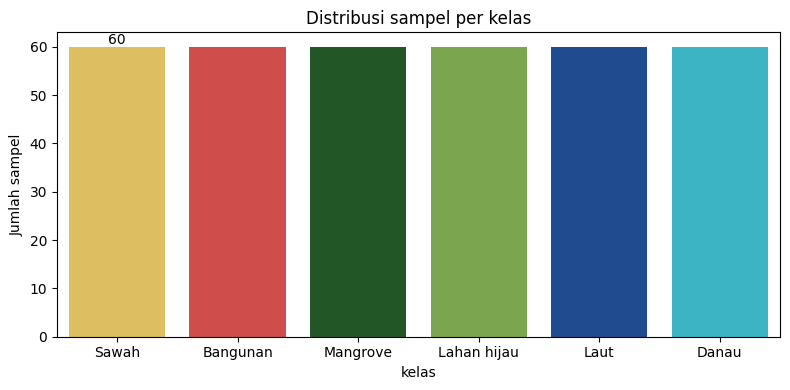

In [ ]:
jml = df["kelas"].value_counts().reindex(NAMA_KELAS)
print("Jumlah kelas :", df["kelas"].nunique())
print("Jumlah data  :", len(df))
display(jml.to_frame("jumlah sampel"))

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=jml.index, y=jml.values, palette=[WARNA_KELAS[k] for k in jml.index])
ax.bar_label(ax.containers[0])
plt.ylabel("Jumlah sampel"); plt.title("Distribusi sampel per kelas")
plt.tight_layout(); plt.show()

**Penjelasan kode:** jumlah sampel per kelas dalam tabel dan diagram batang.

### 4.2 Statistik dan Pola Spektral

Statistik deskriptif menunjukkan sebaran nilai fitur. Rata-rata band per kelas digunakan untuk membandingkan tanda tangan spektral, sedangkan boxplot memperlihatkan variasi indeks dalam tiap kelas. Matriks korelasi membantu melihat fitur yang memiliki pola hubungan serupa. Grafik tersebut memberi gambaran awal, tetapi tidak menggantikan evaluasi model pada data uji.

,count,mean,std,min,25%,50%,75%,max
B2,360.0,0.0509,0.0501,0.0057,0.0263,0.0395,0.0632,0.6464
B3,360.0,0.0698,0.0500,0.0136,0.0454,0.0610,0.0828,0.6637
B4,360.0,0.0561,0.0581,0.0056,0.0243,0.0348,0.0701,0.6565
B5,360.0,0.0896,0.0600,0.0050,0.0476,0.0882,0.1164,0.6804
B6,360.0,0.1614,0.1113,0.0000,0.0308,0.1906,0.2457,0.7784
B7,360.0,0.1860,0.1309,0.0000,0.0320,0.2148,0.2886,0.8282
B8,360.0,0.1856,0.1354,0.0000,0.0234,0.2115,0.2924,0.8192
B8A,360.0,0.1992,0.1442,0.0000,0.0233,0.2311,0.3142,0.8513
B11,360.0,0.1252,0.1004,0.0039,0.0153,0.1247,0.1855,0.6126
B12,360.0,0.0800,0.0854,0.0033,0.0133,0.0507,0.0950,0.4658


,B2,B3,B4,B5,B6,B7,B8,B8A,B11,B12,NDVI,NDWI,MNDWI,NDBI,NDRE,EVI,SAVI,BSI
kelas,,,,,,,,,,,,,,,,,,
Sawah,0.056,0.078,0.070,0.114,0.210,0.244,0.240,0.263,0.172,0.098,0.536,-0.491,-0.366,-0.159,0.341,0.339,0.310,-0.102
Bangunan,0.098,0.117,0.134,0.162,0.203,0.220,0.218,0.235,0.275,0.238,0.257,-0.318,-0.421,0.118,0.148,0.161,0.152,0.129
Mangrove,0.024,0.054,0.029,0.094,0.254,0.298,0.302,0.324,0.111,0.043,0.813,-0.684,-0.334,-0.464,0.515,0.523,0.488,-0.398
Lahan hijau,0.037,0.058,0.039,0.092,0.252,0.303,0.312,0.331,0.161,0.076,0.816,-0.719,-0.525,-0.321,0.565,0.532,0.483,-0.284
Laut,0.057,0.061,0.036,0.034,0.021,0.021,0.018,0.018,0.014,0.012,-0.282,0.516,0.581,-0.122,-0.268,-0.057,-0.047,-0.221
Danau,0.034,0.050,0.030,0.041,0.028,0.030,0.024,0.025,0.019,0.013,-0.348,0.527,0.542,0.020,-0.454,-0.019,-0.022,-0.058


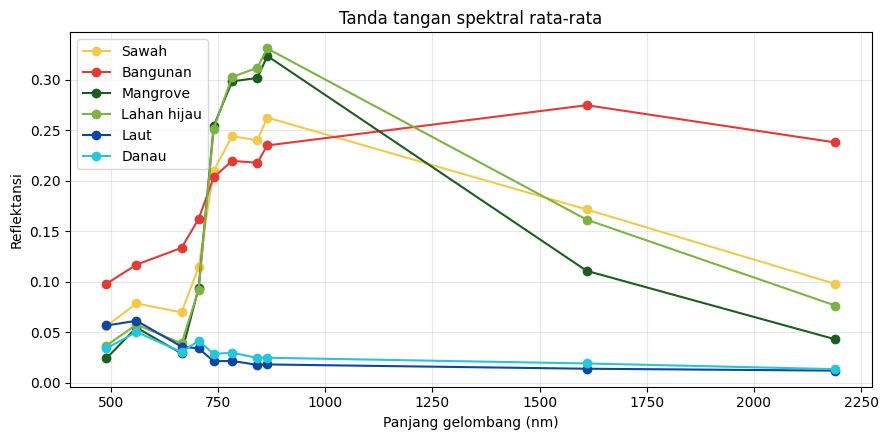

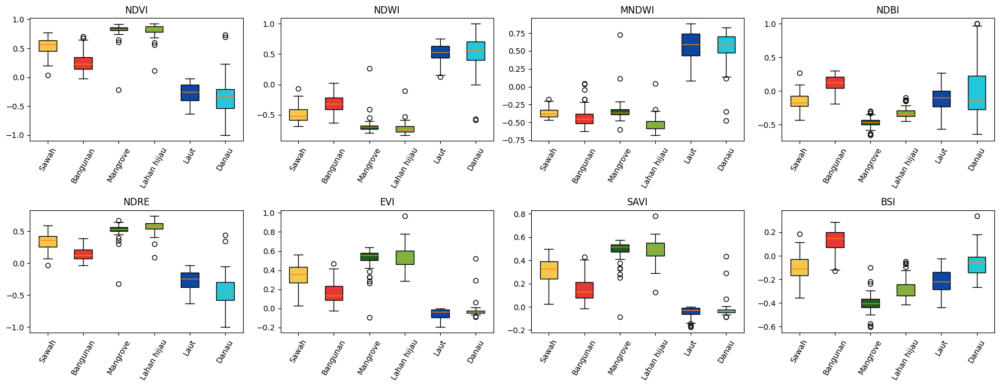

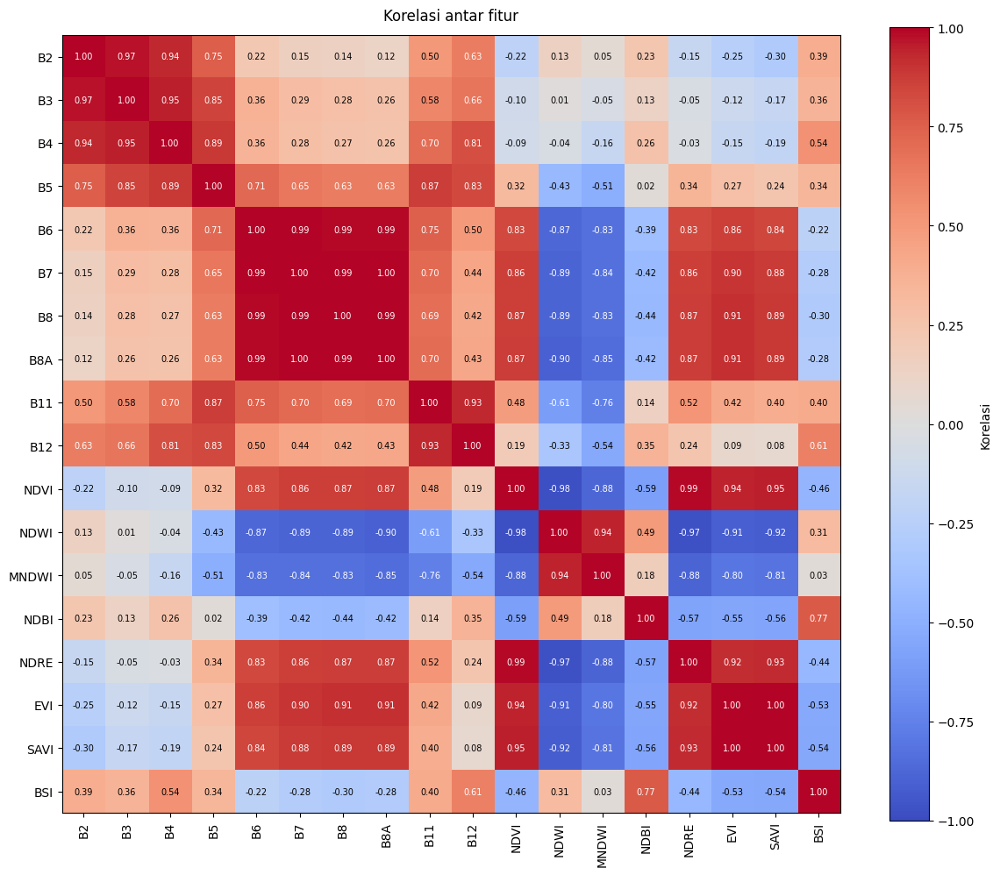

In [ ]:
rata = df.groupby("kelas")[NAMA_FITUR].mean().reindex([KELAS[k][0] for k in KELAS])
display(df[NAMA_FITUR].describe().T.round(4))
display(rata.round(3))
warna = {n: w for n, w in KELAS.values()}

# Tanda tangan spektral: rata-rata pantulan tiap kelas pada tiap band
pjg = [490, 560, 665, 705, 740, 783, 842, 865, 1610, 2190]
plt.figure(figsize=(9, 4.5))
for k in rata.index:
    plt.plot(pjg, rata.loc[k, NAMA_BAND].values, marker="o", label=k, color=warna[k])
plt.xlabel("Panjang gelombang (nm)"); plt.ylabel("Reflektansi")
plt.title("Tanda tangan spektral rata-rata"); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.show()

# Sebaran indeks per kelas
fig, ax = plt.subplots(2, 4, figsize=(18, 7))
for a, f in zip(ax.ravel(), NAMA_INDEKS):
    data = [df.loc[df.kelas == k, f] for k in rata.index]
    bp = a.boxplot(data, patch_artist=True)
    a.set_xticks(range(1, len(rata.index) + 1))
    a.set_xticklabels(list(rata.index))
    for p, k in zip(bp["boxes"], rata.index):
        p.set_facecolor(warna[k])
    a.set_title(f); a.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

# Korelasi antar fitur (angka ditampilkan di tiap kotak)
korelasi = df[NAMA_FITUR].corr()
n = len(NAMA_FITUR)
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(korelasi, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(n)); ax.set_xticklabels(NAMA_FITUR, rotation=90)
ax.set_yticks(range(n)); ax.set_yticklabels(NAMA_FITUR)
for i in range(n):
    for j in range(n):
        v = korelasi.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.6 else "black")   # teks putih di kotak yang gelap
fig.colorbar(im, ax=ax, label="Korelasi")
ax.set_title("Korelasi antar fitur", pad=12)
fig.tight_layout(); plt.show()

**Penjelasan kode:** statistik fitur, tanda tangan spektral, boxplot indeks, dan korelasi antarfitur.

## 5. Pemodelan

### 5.1 Pembagian Data Training dan Testing

Dataset dibagi menjadi data training sebesar 80% dan data testing sebesar 20%. Parameter `stratify` menjaga agar proporsi kelas tetap terwakili pada kedua bagian. Data testing disimpan untuk evaluasi akhir dan tidak digunakan dalam pemilihan model.

### 5.1 Normalisasi Z-score dan Pembagian Dataset

Fitur dinormalisasi menggunakan Z-score melalui `StandardScaler` di dalam pipeline model. Secara konsep, nilai standar dihitung dengan rumus:

$$
z = \frac{x - \mu}{\sigma}
$$

dengan $x$ adalah nilai fitur, $\\mu$ rata-rata fitur pada data training, dan $\\sigma$ standar deviasinya. Normalisasi penting karena band dan indeks dapat memiliki skala berbeda, terutama untuk KNN yang memakai jarak. Normalisasi membantu agar skala besar tidak mendominasi perhitungan. Scaler di-fit hanya pada data training dalam setiap fold validasi untuk menghindari *data leakage*.

Dataset dibagi menjadi data training dan testing secara stratifikasi per kelas. Pemilihan model dilakukan berdasarkan akurasi validasi silang pada training; data testing hanya digunakan untuk evaluasi akhir.


In [ ]:
X = df[NAMA_FITUR].values
y = df["kelas_id"].values

# Pembagian per poligon, proporsional untuk tiap kelas
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=1 - TRAIN_FRAC,
                                  stratify=y, random_state=SEED)
X_tr, y_tr, X_te, y_te = X[idx_tr], y[idx_tr], X[idx_te], y[idx_te]

rekap = pd.DataFrame({
    "Kelas": [KELAS[k][0] for k in KELAS],
    "Training": [int((y_tr == k).sum()) for k in KELAS],
    "Testing": [int((y_te == k).sum()) for k in KELAS],
    "Total": [int((y == k).sum()) for k in KELAS],
})
rekap.loc[len(rekap)] = ["Jumlah", rekap.Training.sum(), rekap.Testing.sum(), rekap.Total.sum()]
display(rekap)
log(f"Jumlah kelas: {len(KELAS)} | data latih: {len(y_tr)} poligon | data uji: {len(y_te)} poligon")

,Kelas,Training,Testing,Total
0,Sawah,48,12,60
1,Bangunan,48,12,60
2,Mangrove,48,12,60
3,Lahan hijau,48,12,60
4,Laut,48,12,60
5,Danau,48,12,60
6,Jumlah,288,72,360


Jumlah kelas: 6 | data latih: 288 poligon | data uji: 72 poligon


**Mengapa normalisasi Z-score penting?** Setiap band dan indeks Sentinel-2 dapat memiliki rentang nilai yang berbeda. Z-score menyetarakan skala fitur sehingga fitur yang nilainya besar tidak otomatis lebih dominan. Ini terutama penting untuk KNN yang menghitung jarak antar sampel. `StandardScaler` di-fit hanya pada data training (di dalam pipeline/CV), kemudian diterapkan ke data uji dan data peta; cara ini mencegah *data leakage*.

**Pembagian data:** data dibagi menjadi training dan testing secara stratifikasi per kelas. Data training digunakan untuk membandingkan model dan mencari hyperparameter, sedangkan data testing dipakai untuk evaluasi akhir.


### 5.2 Perbandingan Model

Tiga algoritma dibandingkan: Decision Tree, Random Forest, dan K-Nearest Neighbors (KNN). Ketiganya menggunakan normalisasi Z-score melalui `StandardScaler` di dalam pipeline. Normalisasi sangat berpengaruh pada KNN karena algoritma ini menghitung jarak, sedangkan pada pohon keputusan pengaruh skala biasanya kecil. Model dibandingkan menggunakan validasi silang pada data training. Model dengan **akurasi CV tertinggi** dipilih; jika akurasinya sama, F1 macro digunakan sebagai pembanding. Akurasi testing ditampilkan untuk mengevaluasi model terpilih, bukan untuk memilihnya.


In [ ]:
# Semua model memakai normalisasi Z-score di dalam pipeline.
# StandardScaler di-fit hanya pada data latih di setiap fold CV, sehingga tidak terjadi data leakage.
# Regularisasi pohon membatasi kompleksitas model untuk mengurangi overfitting.
MODEL = {
    "Decision Tree": make_pipeline(
        StandardScaler(),
        DecisionTreeClassifier(class_weight="balanced", random_state=SEED,
                               max_depth=10, min_samples_split=5, min_samples_leaf=3)
    ),
    "Random Forest": make_pipeline(
        StandardScaler(),
        RandomForestClassifier(n_estimators=N_TREES, class_weight="balanced",
                               max_depth=20, min_samples_split=5, min_samples_leaf=2,
                               max_features="sqrt", random_state=SEED, n_jobs=-1)
    ),
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5, weights="distance")
    ),
}

# Model dipilih berdasarkan akurasi validasi silang pada data training,
# bukan akurasi data testing, agar data testing tetap menjadi evaluasi akhir.
lipat = int(max(2, min(5, np.bincount(y_tr)[np.bincount(y_tr) > 0].min())))
cv = RepeatedStratifiedKFold(n_splits=lipat, n_repeats=3, random_state=SEED)

baris = []
for nama, mdl in MODEL.items():
    hs = cross_validate(mdl, X_tr, y_tr, cv=cv, n_jobs=1,
                        scoring={"acc": "accuracy", "f1": "f1_macro"})
    mdl.fit(X_tr, y_tr)
    baris.append({"Model": nama,
                  "Akurasi CV": hs["test_acc"].mean(),
                  "F1 macro CV": hs["test_f1"].mean(),
                  "Akurasi uji": accuracy_score(y_te, mdl.predict(X_te)),
                  "F1 macro uji": f1_score(y_te, mdl.predict(X_te), average="macro")})

banding = pd.DataFrame(baris).sort_values(
    ["Akurasi CV", "F1 macro CV"], ascending=False
).reset_index(drop=True)
display(banding.round(4))

nama_terbaik = banding.loc[0, "Model"]
log(f"Model terpilih berdasarkan akurasi CV tertinggi ({lipat} lipatan x 3 ulangan): {nama_terbaik}")


,Model,Akurasi CV,F1 macro CV,Akurasi uji,F1 macro uji
0,Random Forest,0.8981,0.8974,0.9167,0.9137
1,KNN,0.8901,0.8892,0.9028,0.9004
2,Decision Tree,0.8241,0.8222,0.8889,0.8869


Model terpilih berdasarkan akurasi CV tertinggi (5 lipatan x 3 ulangan): Random Forest


**Penjelasan kode:** tiga model dibandingkan dengan validasi silang; model dengan hasil terbaik dipilih.

## 6. Eksperimen dan Pengurangan Overfitting

Eksperimen membandingkan rasio training-testing, kombinasi fitur, dan hyperparameter. Untuk mengurangi overfitting, kedalaman pohon dibatasi serta nilai minimum sampel pada daun dan percabangan ditingkatkan. Grid search memilih pengaturan berdasarkan validasi silang pada data training. Akurasi training saja tidak cukup: model yang terlalu menghafal data training bisa memiliki akurasi tinggi tetapi buruk saat memprediksi data baru. Karena itu, performa akhir tetap diperiksa menggunakan data testing yang terpisah.


In [ ]:
# Eksperimen dilakukan pada model terpilih; skor = akurasi CV berulang
def skor_cv(mdl, kolom, Xd, yd, n_rep=3):
    lp = int(max(2, min(5, np.bincount(yd)[np.bincount(yd) > 0].min())))
    c = RepeatedStratifiedKFold(n_splits=lp, n_repeats=n_rep, random_state=SEED)
    return cross_val_score(clone(mdl), Xd[:, kolom], yd, cv=c, scoring="accuracy")

# 1. Rasio pembagian data
baris_r = []
for ts in [0.2, 0.3, 0.4]:
    sk = []
    for r in range(10):
        a, b, c_, d = train_test_split(X, y, test_size=ts, stratify=y, random_state=SEED + r)
        sk.append(accuracy_score(d, clone(MODEL[nama_terbaik]).fit(a, c_).predict(b)))
    baris_r.append({"Rasio train:test": f"{int((1 - ts) * 100)}:{int(ts * 100)}",
                    "Akurasi rata-rata": np.mean(sk), "Std": np.std(sk)})
eksp_rasio = pd.DataFrame(baris_r)
display(eksp_rasio.round(4))

# 2. Kombinasi fitur
idx = {n: i for i, n in enumerate(NAMA_FITUR)}
skenario = {
    "A. 4 band 10 m (B2,B3,B4,B8)": ["B2", "B3", "B4", "B8"],
    "B. 10 band": NAMA_BAND,
    "C. 8 indeks": NAMA_INDEKS,
    "D. Indeks pilihan (NDVI,MNDWI,NDBI,BSI)": ["NDVI", "MNDWI", "NDBI", "BSI"],
    "E. Band + indeks (18 fitur)": NAMA_FITUR,
}
baris_f = []
for nm, kol in skenario.items():
    sk = skor_cv(MODEL[nama_terbaik], [idx[k] for k in kol], X_tr, y_tr)
    baris_f.append({"Skenario": nm, "Jumlah fitur": len(kol),
                    "Akurasi CV": sk.mean(), "Std": sk.std()})
eksp_fitur = pd.DataFrame(baris_f).sort_values("Akurasi CV", ascending=False).reset_index(drop=True)
display(eksp_fitur.round(4))

# 3. Hyperparameter (Grid Search)
GRID = {
    "Random Forest": {
        "randomforestclassifier__n_estimators": [200, 400],
        "randomforestclassifier__max_depth": [None, 10, 20],
        "randomforestclassifier__min_samples_leaf": [1, 2],
        "randomforestclassifier__min_samples_split": [2, 5, 10],
    },
    "Decision Tree": {
        "decisiontreeclassifier__max_depth": [None, 5, 10, 20],
        "decisiontreeclassifier__min_samples_leaf": [1, 2, 5],
        "decisiontreeclassifier__min_samples_split": [2, 5, 10],
    },
    "KNN": {
        "kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 9],
        "kneighborsclassifier__weights": ["uniform", "distance"],
    },
    "SVM": {
        "svc__C": [0.1, 1, 10],
        "svc__kernel": ["rbf"],
        "svc__gamma": ["scale", "auto"],
    },
    "Gradient Boosting": {
        "gradientboostingclassifier__n_estimators": [100, 200],
        "gradientboostingclassifier__learning_rate": [0.03, 0.1],
        "gradientboostingclassifier__max_depth": [2, 3],
        "gradientboostingclassifier__min_samples_leaf": [1, 2],
    },
}[nama_terbaik]

lp = int(max(
    2,
    min(5, np.bincount(y_tr)[np.bincount(y_tr) > 0].min())
))

gs = GridSearchCV(
    estimator=clone(MODEL[nama_terbaik]),
    param_grid=GRID,
    scoring="accuracy",
    cv=RepeatedStratifiedKFold(
        n_splits=lp,
        n_repeats=3,
        random_state=SEED
    ),
    n_jobs=-1,
    error_score="raise"
)

gs.fit(X_tr, y_tr)

eksp_hp = pd.DataFrame(gs.cv_results_)[
    ["params", "mean_test_score", "std_test_score"]
]

eksp_hp = (
    eksp_hp.sort_values("mean_test_score", ascending=False)
    .head(8)
    .reset_index(drop=True)
)

display(eksp_hp.round(4))

log(
    f"Hyperparameter terbaik: {gs.best_params_} | "
    f"Akurasi CV {gs.best_score_:.4f}"
)

# Model terbaik hasil tuning digunakan pada evaluasi berikutnya
MODEL[nama_terbaik] = gs.best_estimator_

,Rasio train:test,Akurasi rata-rata,Std
0,80:20,0.9222,0.0299
1,70:30,0.9083,0.0345
2,60:40,0.9056,0.0283


,Skenario,Jumlah fitur,Akurasi CV,Std
0,E. Band + indeks (18 fitur),18,0.9028,0.0372
1,B. 10 band,10,0.8889,0.0383
2,C. 8 indeks,8,0.8727,0.0395
3,"D. Indeks pilihan (NDVI,MNDWI,NDBI,BSI)",4,0.8403,0.0477
4,"A. 4 band 10 m (B2,B3,B4,B8)",4,0.7801,0.0331


,params,mean_test_score,std_test_score
0,"{'randomforestclassifier__max_depth': None, 'r...",0.9028,0.0372
1,"{'randomforestclassifier__max_depth': 10, 'ran...",0.9028,0.0372
2,"{'randomforestclassifier__max_depth': 20, 'ran...",0.9028,0.0372
3,"{'randomforestclassifier__max_depth': None, 'r...",0.9005,0.0403
4,"{'randomforestclassifier__max_depth': 20, 'ran...",0.9005,0.0403
5,"{'randomforestclassifier__max_depth': 20, 'ran...",0.9005,0.0343
6,"{'randomforestclassifier__max_depth': 10, 'ran...",0.9005,0.0403
7,"{'randomforestclassifier__max_depth': None, 'r...",0.9005,0.0343


Hyperparameter terbaik: {'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__min_samples_split': 2, 'randomforestclassifier__n_estimators': 200} | Akurasi CV 0.9028


**Penjelasan kode:** eksperimen rasio data, kombinasi fitur, dan hyperparameter pada model terpilih.

### 6.4 Model Final dan Evaluasi

Model pilihan dinilai pada data testing menggunakan akurasi, presisi, recall, F1-score, dan Cohen's Kappa. Akurasi menunjukkan proporsi prediksi yang benar secara keseluruhan. Presisi dan recall menilai ketepatan prediksi serta kemampuan model menemukan anggota suatu kelas, sementara F1-score merangkum keduanya. Confusion matrix digunakan untuk melihat pasangan kelas yang masih sering tertukar.

,Prediksi: Sawah,Prediksi: Bangunan,Prediksi: Mangrove,Prediksi: Lahan hijau,Prediksi: Laut,Prediksi: Danau
Aktual: Sawah,12,0,0,0,0,0
Aktual: Bangunan,1,11,0,0,0,0
Aktual: Mangrove,0,0,12,0,0,0
Aktual: Lahan hijau,1,1,1,9,0,0
Aktual: Laut,0,0,0,0,12,0
Aktual: Danau,0,0,0,0,0,12


              precision    recall  f1-score   support

       Sawah      0.857     1.000     0.923        12
    Bangunan      0.917     0.917     0.917        12
    Mangrove      0.923     1.000     0.960        12
 Lahan hijau      1.000     0.750     0.857        12
        Laut      1.000     1.000     1.000        12
       Danau      1.000     1.000     1.000        12

    accuracy                          0.944        72
   macro avg      0.949     0.944     0.943        72
weighted avg      0.949     0.944     0.943        72

Random Forest | Overall Accuracy: 0.9444 | Kappa: 0.9333


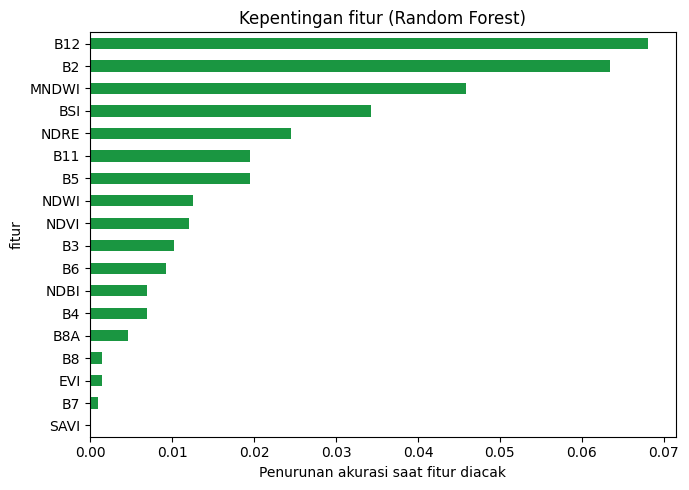

In [ ]:
model = MODEL[nama_terbaik]          # sudah dilatih pada data latih
pred_te = model.predict(X_te)
nama_kelas = [KELAS[k][0] for k in KELAS]

cm = pd.DataFrame(confusion_matrix(y_te, pred_te, labels=list(KELAS)),
                  index=[f"Aktual: {n}" for n in nama_kelas],
                  columns=[f"Prediksi: {n}" for n in nama_kelas])
display(cm)

acc = accuracy_score(y_te, pred_te)
kappa = cohen_kappa_score(y_te, pred_te)
laporan = classification_report(y_te, pred_te, labels=list(KELAS),
                                target_names=nama_kelas, digits=3, output_dict=True,
                                zero_division=0)
print(classification_report(y_te, pred_te, labels=list(KELAS), target_names=nama_kelas,
                            digits=3, zero_division=0))
log(f"{nama_terbaik} | Overall Accuracy: {acc:.4f} | Kappa: {kappa:.4f}")

# Kepentingan fitur dengan permutasi pada data uji
pi = permutation_importance(model, X_te, y_te, n_repeats=30, random_state=SEED,
                            scoring="accuracy")
fi = pd.DataFrame({"fitur": NAMA_FITUR, "kepentingan": pi.importances_mean}
                  ).sort_values("kepentingan")
fi.plot(x="fitur", y="kepentingan", kind="barh", figsize=(7, 5), legend=False, color="#1a9641")
plt.xlabel("Penurunan akurasi saat fitur diacak")
plt.title(f"Kepentingan fitur ({nama_terbaik})")
plt.tight_layout()
plt.show()

# Model akhir dilatih ulang dengan seluruh poligon
model_akhir = MODEL[nama_terbaik].fit(X, y)

**Penjelasan kode:** evaluasi pada data uji (confusion matrix, metrik per kelas, akurasi, Kappa) dan kepentingan fitur.

In [ ]:
terlemah = min(KELAS, key=lambda k: laporan[KELAS[k][0]]["f1-score"])
print(f"Model terbaik: {nama_terbaik}")
print(f"Akurasi uji: {acc:.3f} | Kappa: {kappa:.3f}")
print(f"Kelas dengan F1 terendah: {KELAS[terlemah][0]} "
      f"({laporan[KELAS[terlemah][0]]['f1-score']:.3f})")
print(f"Jumlah data: {len(y_tr)} poligon latih, {len(y_te)} poligon uji, {len(KELAS)} kelas")

Model terbaik: Random Forest
Akurasi uji: 0.944 | Kappa: 0.933
Kelas dengan F1 terendah: Lahan hijau (0.857)
Jumlah data: 288 poligon latih, 72 poligon uji, 6 kelas


**Penjelasan kode:** ringkasan model terpilih, skor uji, kelas dengan F1 terendah, dan jumlah data.

### 7.0 Sumber Citra untuk Peta: Google Earth Engine

Untuk pemrosesan peta area luas, notebook menggunakan Google Earth Engine (GEE) sebagai sumber citra. Koleksi Sentinel-2 Surface Reflectance disaring berdasarkan rentang tanggal dan persentase awan, lalu piksel awan serta bayangannya disisihkan melalui band SCL. Komposit median dibuat dengan rentang dan band yang disesuaikan dengan pengolahan sampel.

Akses Earth Engine perlu diotorisasi pada sesi pertama. Data sampel dan data untuk peta berasal dari jalur pengambilan yang berbeda, sehingga perbedaan hasil tetap mungkin terjadi akibat waktu citra dan ketersediaan data.

In [ ]:
# Pengganti Copernicus untuk peta: Google Earth Engine (GEE)
import json, subprocess, sys
try:
    import ee
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "earthengine-api"], check=True)
    import ee

GEE_PROJECT = "sawah-510601"          # ID proyek Google Cloud yang sudah terdaftar di Earth Engine

try:
    ee.Initialize(project=GEE_PROJECT)
except Exception:
    ee.Authenticate()                 # buka tautan, login, izinkan, tempel kode
    ee.Initialize(project=GEE_PROJECT)

_BAND_EE = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]


def _mask_awan(img):
    """Buang bayangan awan (3), awan (8, 9), cirrus (10), dan salju (11) berdasarkan band SCL."""
    scl = img.select("SCL")
    ok = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)).And(scl.neq(11))
    return img.updateMask(ok)


# Area peta berbentuk kotak penuh (bounding box + buffer)
ee_batas = ee.Geometry.Rectangle(list(BATAS_PETA.bounds), proj="EPSG:4326", geodesic=False)
print("Geometri area GEE (kotak) siap:", ee_batas.type().getInfo())

_kol = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(ee_batas)
        .filterDate(TANGGAL_MULAI, TANGGAL_AKHIR)
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", MAX_CLOUD)))
if HANYA_SENTINEL_2A:
    _kol = _kol.filter(ee.Filter.eq("SPACECRAFT_NAME", "Sentinel-2A"))

n_scene = int(_kol.size().getInfo())
print("Jumlah scene Sentinel-2 yang lolos filter:", n_scene)
if n_scene == 0:
    raise RuntimeError("Tidak ada scene yang lolos filter. Perlebar periode, naikkan MAX_CLOUD, "
                       "atau set HANYA_SENTINEL_2A = False.")

# Komposit median bebas awan (reflektansi 0-1); piksel kosong -> -9999 -> NaN
_KOMPOSIT = (_kol.map(_mask_awan).select(_BAND_EE).median()
             .divide(10000).toFloat().unmask(-9999))


def ambil_median(bbox, ukuran):
    """Komposit median 10 band untuk bbox dan ukuran (lebar, tinggi); hasil (tinggi, lebar, 10)."""
    try:
        barat, selatan, timur, utara = tuple(bbox)
    except TypeError:
        barat, selatan, timur, utara = bbox.min_x, bbox.min_y, bbox.max_x, bbox.max_y
    w, h = int(ukuran[0]), int(ukuran[1])
    arr = ee.data.computePixels({
        "expression": _KOMPOSIT,
        "fileFormat": "NUMPY_NDARRAY",
        "grid": {"dimensions": {"width": w, "height": h},
                 "affineTransform": {"scaleX": (timur - barat) / w, "shearX": 0, "translateX": barat,
                                     "shearY": 0, "scaleY": -(utara - selatan) / h, "translateY": utara},
                 "crsCode": "EPSG:4326"}})
    out = np.stack([arr[b] for b in _BAND_EE], axis=-1).astype(np.float32)
    out[out <= -9000] = np.nan
    return out


TILE_PX = 250        # ubin kecil agar permintaan GEE tidak timeout
print("Uji satu ubin kecil:", ambil_median((112.7, -7.5, 112.71, -7.49), (64, 64)).shape)

Geometri area GEE (kotak) siap: Polygon
Jumlah scene Sentinel-2 yang lolos filter: 488
Uji satu ubin kecil: (64, 64, 10)


**Penjelasan kode:** inisialisasi Earth Engine, komposit median Sentinel-2 pada kotak area studi, dan fungsi `ambil_median()`.

## 7. Peta Hasil Klasifikasi

### 7.1 Prediksi Piksel di Jawa Timur

Model yang sudah dipilih diterapkan pada citra di dalam batas wilayah studi. Area dihitung per ubin agar kebutuhan memori dan ukuran setiap permintaan tetap terkendali. Hasil sementara disimpan sehingga proses dapat dilanjutkan jika tidak selesai dalam satu kali jalan. Hasil prediksi dipertahankan berbentuk kotak penuh (tanpa dipotong mengikuti batas provinsi); garis batas Jawa Timur ditampilkan di peta sebagai penanda wilayah.

In [ ]:
# Model akhir dilatih dengan seluruh data berlabel
model_peta = clone(MODEL[nama_terbaik]).fit(X, y)


def hex_rgb(h):
    h = h.lstrip("#")
    return [int(h[i:i + 2], 16) for i in (0, 2, 4)]


def klasifikasi_aoi(aoi, skala, tile_px, model):
    """Klasifikasi AOI per ubin; hasil sebagian disimpan agar bisa dilanjutkan."""
    barat, selatan, timur, utara = aoi
    dx = skala / 111320.0                                  # meter -> derajat
    W = int(math.ceil((timur - barat) / dx))
    H = int(math.ceil((utara - selatan) / dx))
    n_tile = math.ceil(H / tile_px) * math.ceil(W / tile_px)
    print(f"Raster {W} x {H} piksel ({W * H:,} piksel), dibagi menjadi {n_tile} ubin")

    label = np.full((H, W), -1, dtype=np.int8)
    if FILE_PETA.exists():                                 # lanjutkan hasil sebelumnya
        try:
            lama = np.load(FILE_PETA, allow_pickle=True)
            if (lama["label"].shape == (H, W) and "versi" in lama.files
                    and str(lama["versi"]) == VERSI_PETA):
                label = lama["label"].copy()
                print(f"Melanjutkan raster yang ada ({np.mean(label != -1):.1%} terisi)")
            else:
                print("Cache label_peta.npz lama (masih bermasker / ukuran beda) diabaikan, dihitung ulang.")
        except Exception:
            pass

    n, gagal = 0, []
    for r0 in range(0, H, tile_px):
        for c0 in range(0, W, tile_px):
            r1, c1 = min(r0 + tile_px, H), min(c0 + tile_px, W)
            n += 1
            if np.mean(label[r0:r1, c0:c1] != -1) > 0.5:   # ubin sudah terisi
                print(f"\rUbin {n}/{n_tile} (sudah ada, dilewati)      ", end="")
                continue
            bbox = BBox([barat + c0 * dx, utara - r1 * dx, barat + c1 * dx, utara - r0 * dx],
                        crs=CRS.WGS84)
            arr = None
            for percobaan in range(3):
                try:
                    arr = ambil_median(bbox, (c1 - c0, r1 - r0))
                    break
                except Exception as e:
                    if percobaan == 2:
                        gagal.append((r0, c0, str(e)[:150]))
                        print(f"\n[Galat ubin {n}]: {str(e)[:200]}")
                    time.sleep(10)
            print(f"\rUbin {n}/{n_tile}                              ", end="")
            if arr is None:
                continue
            h, w = arr.shape[:2]
            d = tambah_indeks(pd.DataFrame(arr.reshape(-1, len(BAND_ASLI)), columns=BAND_ASLI))
            d = d.replace([np.inf, -np.inf], np.nan)
            valid = d[FITUR_SEMUA].notna().all(axis=1).values
            if valid.any():
                pred = model.predict(d.loc[valid, FITUR_SEMUA].values)   # kode kelas 0..5
                kk = np.full(h * w, -1, dtype=np.int8)
                kk[valid] = pred
                label[r0:r0 + h, c0:c0 + w] = kk.reshape(h, w)
            np.savez_compressed(FILE_PETA, label=label, versi=VERSI_PETA)   # simpan progres
            time.sleep(2)                                     # jeda agar tidak kena rate limit
    print()
    if gagal:
        print(f"PERINGATAN: {len(gagal)} ubin gagal diunduh. Jalankan sel ini lagi untuk melengkapi.")

    # Tanpa masker: seluruh kotak dipertahankan, batas Jatim hanya garis di peta
    batas_selatan_raster = utara - H * dx
    batas_timur_raster = barat + W * dx
    batas = [[batas_selatan_raster, barat], [utara, batas_timur_raster]]
    return label, batas


label_peta, batas_peta = klasifikasi_aoi(JATIM, SKALA_PETA, TILE_PX, model_peta)
np.savez_compressed(FILE_PETA, label=label_peta, versi=VERSI_PETA)
print("Ukuran raster hasil:", label_peta.shape)

Raster 5079 x 3560 piksel (18,081,240 piksel), dibagi menjadi 315 ubin
Melanjutkan raster yang ada (1.7% terisi)
Ubin 315/315                              
Ukuran raster hasil: (3560, 5079)


**Penjelasan kode:** klasifikasi per ubin 250 × 250 piksel. Hasil berbentuk kotak penuh; piksel tanpa data bernilai -1 dan transparan.

In [ ]:
# Simpan satu overlay transparan untuk setiap kelas agar checkbox peta
# mengaktifkan/menonaktifkan HASIL KLASIFIKASI kelas tersebut, bukan sampel latih.
H, W = label_peta.shape
DATA_APP.mkdir(exist_ok=True)
layer_kelas = {}
for idx, (nama, warna) in enumerate(KELAS.values()):
    rgba_kelas = np.zeros((H, W, 4), dtype=np.uint8)
    rgba_kelas[label_peta == idx] = hex_rgb(warna) + [255]
    nama_file = f"hasil_klasifikasi_kelas_{idx}.png"
    Image.fromarray(rgba_kelas).save(DATA_APP / nama_file)
    layer_kelas[str(idx)] = nama_file

# Overlay gabungan tetap disimpan untuk keperluan unduh/kompatibilitas.
rgba = np.zeros((H, W, 4), dtype=np.uint8)
for idx, (nama, warna) in enumerate(KELAS.values()):
    rgba[label_peta == idx] = hex_rgb(warna) + [255]
Image.fromarray(rgba).save(DATA_APP / "hasil_klasifikasi.png")

# Luas piksel bergantung pada lintang (1 piksel = SKALA_PETA m di khatulistiwa)
dx = SKALA_PETA / 111320.0
lat_baris = JATIM[3] - (np.arange(H) + 0.5) * dx
ha_baris = (SKALA_PETA ** 2) * np.cos(np.radians(lat_baris)) / 10_000
ha_piksel = np.repeat(ha_baris[:, None], W, axis=1)
from rasterio.features import geometry_mask
from rasterio.transform import from_bounds as _fb
_tr = _fb(batas_peta[0][1], batas_peta[0][0], batas_peta[1][1], batas_peta[1][0], W, H)
di_jatim = geometry_mask([mapping(BATAS_GEOM)], out_shape=(H, W), transform=_tr, invert=True)
m = (label_peta >= 0) & di_jatim
jumlah = np.bincount(label_peta[m].astype(int), minlength=len(KELAS))
luas_ha = np.bincount(label_peta[m].astype(int), weights=ha_piksel[m], minlength=len(KELAS))

total_luas = pd.DataFrame({"Jumlah piksel": jumlah, "luas_ha": luas_ha.round(1)}, index=NAMA_KELAS)
total_luas["persen"] = (100 * total_luas["luas_ha"] / total_luas["luas_ha"].sum()).round(2)
total_luas.index.name = "kelas"
print(f"Piksel tanpa data (di kotak): {(label_peta < 0).sum():,} dari {label_peta.size:,}")
display(total_luas)

luas = (total_luas.reset_index()[["kelas", "luas_ha", "persen"]]
        .assign(aoi="Jawa Timur", tanggal=f"{TANGGAL_MULAI} s.d. {TANGGAL_AKHIR}", awan=MAX_CLOUD))
hasil_aoi = {"Jawa Timur": {"png": "hasil_klasifikasi.png",
                            "layers": layer_kelas, "bounds": batas_peta,
                            "tanggal": f"{TANGGAL_MULAI} s.d. {TANGGAL_AKHIR}", "awan": MAX_CLOUD}}


Piksel tanpa data (di kotak): 8,498 dari 18,081,240


,Jumlah piksel,luas_ha,persen
kelas,,,
Sawah,1074623,1533418.2,31.78
Bangunan,1114506,1591110.8,32.98
Mangrove,25125,35874.9,0.74
Lahan hijau,1131287,1613291.5,33.44
Laut,2004,2862.1,0.06
Danau,33790,48257.9,1.00


**Penjelasan kode:** hasil diubah menjadi gambar berwarna, lalu luas tiap kelas dihitung (hanya di dalam batas Jawa Timur).

### 7.2 Ekspor GeoTIFF

Selain PNG untuk peta interaktif, hasil klasifikasi juga diekspor sebagai
**GeoTIFF** (`hasil_klasifikasi.tif`) agar bisa dibuka langsung di QGIS atau perangkat
lunak SIG lain. Rasternya berformat *paletted* (1 band, nilai 0-5 sesuai `KELAS`,
disertai tabel warna) dengan sistem koordinat EPSG:4326, mengikuti batas dan ukuran
piksel yang sama dengan peta hasil klasifikasi.

In [ ]:
import rasterio
from rasterio.transform import from_bounds as _dari_batas

selatan_tif, barat_tif = batas_peta[0]
utara_tif, timur_tif = batas_peta[1]
H_tif, W_tif = label_peta.shape
transform_tif = _dari_batas(barat_tif, selatan_tif, timur_tif, utara_tif, W_tif, H_tif)

# Piksel tanpa data (-1) diubah ke 255 karena GeoTIFF 8-bit tak bertanda tidak punya nilai negatif.
NODATA_TIF = 255
label_tif = np.where(label_peta < 0, NODATA_TIF, label_peta).astype("uint8")

FILE_TIF = DATA_APP / "hasil_klasifikasi.tif"
with rasterio.open(
    FILE_TIF, "w", driver="GTiff",
    height=H_tif, width=W_tif, count=1, dtype="uint8",
    crs="EPSG:4326", transform=transform_tif, nodata=NODATA_TIF,
    compress="deflate",
) as dst:
    dst.write(label_tif, 1)
    peta_warna = {idx: tuple(hex_rgb(warna) + [255]) for idx, (nama, warna) in KELAS.items()}
    peta_warna[NODATA_TIF] = (0, 0, 0, 0)
    dst.write_colormap(1, peta_warna)
    dst.update_tags(1, **{str(idx): nama for idx, (nama, _) in KELAS.items()})

print("GeoTIFF tersimpan:", FILE_TIF, "| ukuran:", (H_tif, W_tif))

# Unduh otomatis bila dijalankan di Google Colab
try:
    from google.colab import files
    files.download(str(FILE_TIF))
except Exception:
    pass

GeoTIFF tersimpan: /content/data_app/hasil_klasifikasi.tif | ukuran: (3560, 5079)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 7.3 Menyimpan Hasil Pemodelan

Bagian ini menyimpan hasil pemodelan ke dalam folder `data_app`. Berkas yang disiapkan mencakup ringkasan sampel, perbandingan model, confusion matrix, kepentingan fitur, hasil eksperimen, luas kelas, poligon sampel, batas Jawa Timur, dan metadata peta. Berkas-berkas ini dapat dibaca kembali tanpa menjalankan ulang pelatihan model.

In [ ]:
# Ekspor hasil pemodelan
ringkas = rekap.iloc[:-1].copy()
ringkas.insert(1, "Warna", [KELAS[k][1] for k in KELAS])
ringkas.to_csv(DATA_APP / "ringkasan_kelas.csv", index=False)
banding.round(4).to_csv(DATA_APP / "perbandingan_model.csv", index=False)
cm.reset_index().rename(columns={"index": "Kelas"}).to_csv(DATA_APP / "confusion_matrix.csv", index=False)
fi.sort_values("kepentingan", ascending=False).round(4).to_csv(DATA_APP / "fitur_penting.csv", index=False)
luas.to_csv(DATA_APP / "luas_aoi.csv", index=False)
eksp_rasio.round(4).to_csv(DATA_APP / "eksp_rasio.csv", index=False)
eksp_fitur.round(4).to_csv(DATA_APP / "eksp_fitur.csv", index=False)
eksp_hp.astype({"params": str}).round(4).to_csv(DATA_APP / "eksp_hyperparameter.csv", index=False)

# Bila memakai dataset lama (poly = None), titik sampel dibuat dari lon/lat
if poly is not None:
    sampel = poly.assign(warna=poly.kelas_id.map(lambda k: KELAS[k][1]))[
        ["pid", "kelas_id", "kelas", "warna", "geometry"]]
else:
    sampel = gpd.GeoDataFrame(
        df.assign(warna=df.kelas_id.map(lambda k: KELAS[k][1]))[["pid", "kelas_id", "kelas", "warna"]],
        geometry=gpd.points_from_xy(df.lon, df.lat), crs=4326)
sampel.to_file(DATA_APP / "sampel.geojson", driver="GeoJSON")
gdf_batas.to_file(DATA_APP / "batas_jawa_timur.geojson", driver="GeoJSON")

laporan_kelas = (pd.DataFrame({k: laporan[k] for k in NAMA_KELAS}).T
                 [["precision", "recall", "f1-score", "support"]].round(3)
                 .reset_index().rename(columns={"index": "Kelas"}))
laporan_kelas.to_csv(DATA_APP / "laporan_kelas.csv", index=False)

semua = [p for a in hasil_aoi.values() for p in a["bounds"]]
meta = {
    "kelas": {str(k): {"nama": n, "warna": w} for k, (n, w) in KELAS.items()},
    "aoi": hasil_aoi,
    "pusat": [float(np.mean([p[0] for p in semua])), float(np.mean([p[1] for p in semua]))],
    "zoom": 8,
    "model_terbaik": nama_terbaik,
    "akurasi_uji": float(acc),
    "kappa_uji": float(kappa),
}
(DATA_APP / "meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding="utf-8")
log("Hasil tersimpan di folder:", DATA_APP.name)

Hasil tersimpan di folder: data_app


**Penjelasan kode:** tabel hasil disimpan sebagai CSV, sampel dan batas provinsi sebagai GeoJSON, dan `meta.json` berisi legenda dan metrik.

### 7.4 Peta Folium dengan Latar Citra Satelit

Peta interaktif menampilkan hasil klasifikasi di atas citra satelit. Pengguna dapat mengatur transparansi melalui kontrol layer, melihat garis batas Jawa Timur, dan menyalakan atau mematikan poligon sampel. Google Satellite menjadi latar utama, dengan Esri World Imagery sebagai pilihan lain.

In [ ]:
%%writefile peta_util.py
"""Pembuat peta Folium dengan layer hasil klasifikasi terpisah per kelas."""
import json
from pathlib import Path
import folium

GOOGLE_SAT = "https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}"
ESRI_SAT = ("https://server.arcgisonline.com/ArcGIS/rest/services/"
            "World_Imagery/MapServer/tile/{z}/{y}/{x}")


def baca_meta(folder):
    return json.loads((Path(folder) / "meta.json").read_text(encoding="utf-8"))


def buat_peta(folder):
    folder = Path(folder)
    meta = baca_meta(folder)
    kelas, aoi = meta["kelas"], meta["aoi"]
    peta = folium.Map(location=meta.get("pusat", [-7.6, 112.2]),
                      zoom_start=meta.get("zoom", 9), tiles=None, control_scale=True)
    folium.TileLayer(tiles=GOOGLE_SAT, attr="Google", name="Google Satellite",
                     max_zoom=20).add_to(peta)
    folium.TileLayer(tiles=ESRI_SAT, attr="Esri World Imagery",
                     name="Esri World Imagery", show=False, max_zoom=19).add_to(peta)

    batas = []
    for nama_aoi, a in aoi.items():
        bounds = a["bounds"]
        batas += bounds
        # Satu checkbox untuk setiap HASIL PREDIKSI kelas. Jika kelas dimatikan,
        # hanya warna/piksel prediksi kelas itu yang hilang dari peta.
        if a.get("layers"):
            for kid, nama_file in a["layers"].items():
                info = kelas.get(str(kid), {})
                nama_kelas = info.get("nama", f"Kelas {kid}")
                folium.raster_layers.ImageOverlay(
                    image=str(folder / nama_file), bounds=bounds, opacity=0.75,
                    name=f"Hasil klasifikasi: {nama_kelas}", show=True
                ).add_to(peta)
        else:
            folium.raster_layers.ImageOverlay(
                image=str(folder / a["png"]), bounds=bounds, opacity=0.75,
                name=f"Hasil klasifikasi {nama_aoi}"
            ).add_to(peta)

    f_batas = folder / "batas_jawa_timur.geojson"
    if f_batas.exists():
        folium.GeoJson(
            str(f_batas), name="Batas Provinsi Jawa Timur",
            style_function=lambda _f: {"fill": False, "color": "#ffffff", "weight": 2.5}
        ).add_to(peta)

    # Sampel tidak ditampilkan sebagai checkbox default; peta fokus pada hasil klasifikasi.
    baris = "".join(
        f'<div><span style="background:{v["warna"]};width:14px;height:14px;'
        f'display:inline-block;margin-right:6px;"></span>{v["nama"]}</div>'
        for v in kelas.values()
    )
    legenda = ('<div style="position:fixed;bottom:30px;left:30px;z-index:9999;'
               'background:white;padding:10px 14px;border:1px solid #888;'
               'border-radius:6px;font-size:13px;"><b>Hasil klasifikasi</b>'
               f'{baris}<div style="font-size:11px;color:#555;margin-top:4px;">'
               'Area transparan = tanpa data</div></div>')
    peta.get_root().html.add_child(folium.Element(legenda))
    peta.get_root().header.add_child(folium.Element(
        "<style>.leaflet-image-layer {image-rendering: pixelated;}</style>"))
    if batas:
        lat = [p[0] for p in batas]
        lon = [p[1] for p in batas]
        peta.fit_bounds([[min(lat), min(lon)], [max(lat), max(lon)]])
    folium.LayerControl(collapsed=False).add_to(peta)
    return peta


Writing peta_util.py


**Penjelasan kode:** `buat_peta()` membuat peta Folium (Google Satellite dan Esri) dengan hasil klasifikasi sebagai `ImageOverlay`.

Tile Google dipanggil lewat URL XYZ di luar API resmi sehingga dapat melanggar ketentuan layanan Google; untuk penggunaan resmi gunakan Map Tiles API dengan API key.


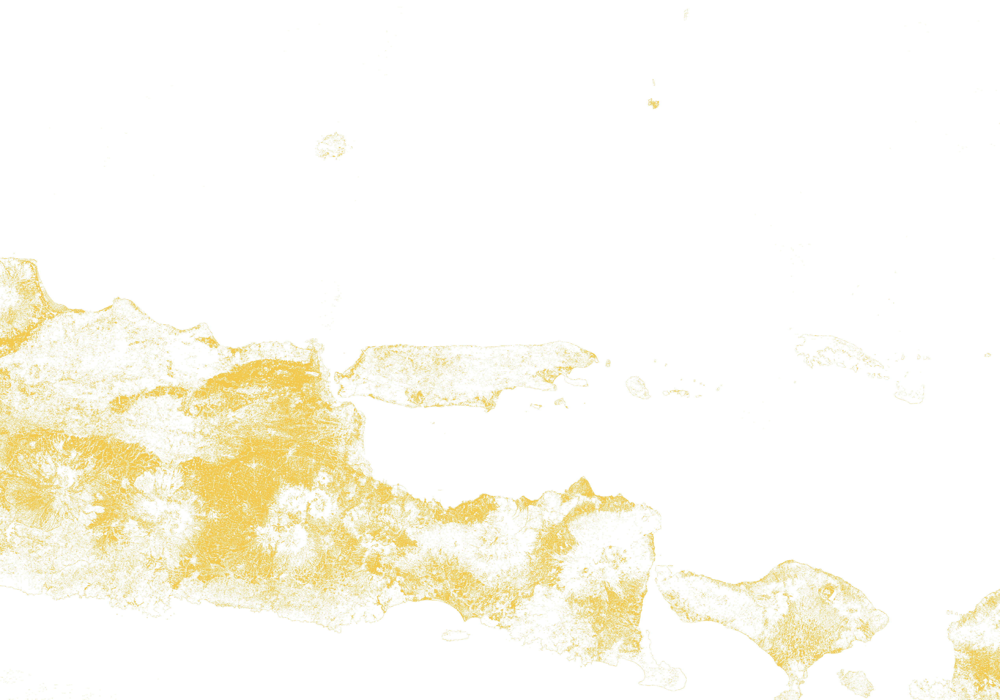
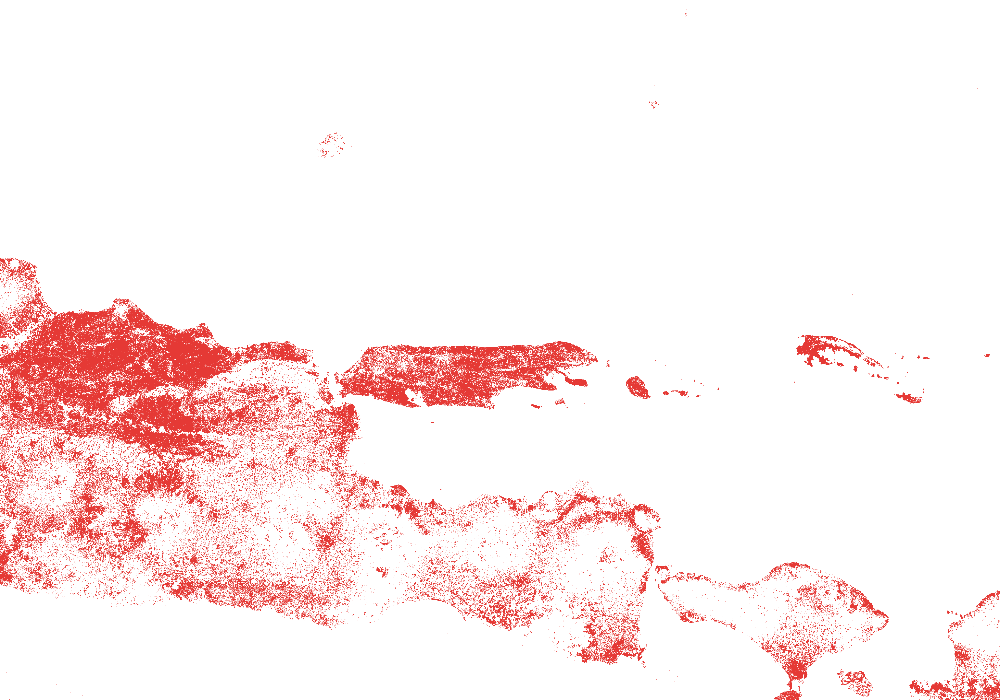
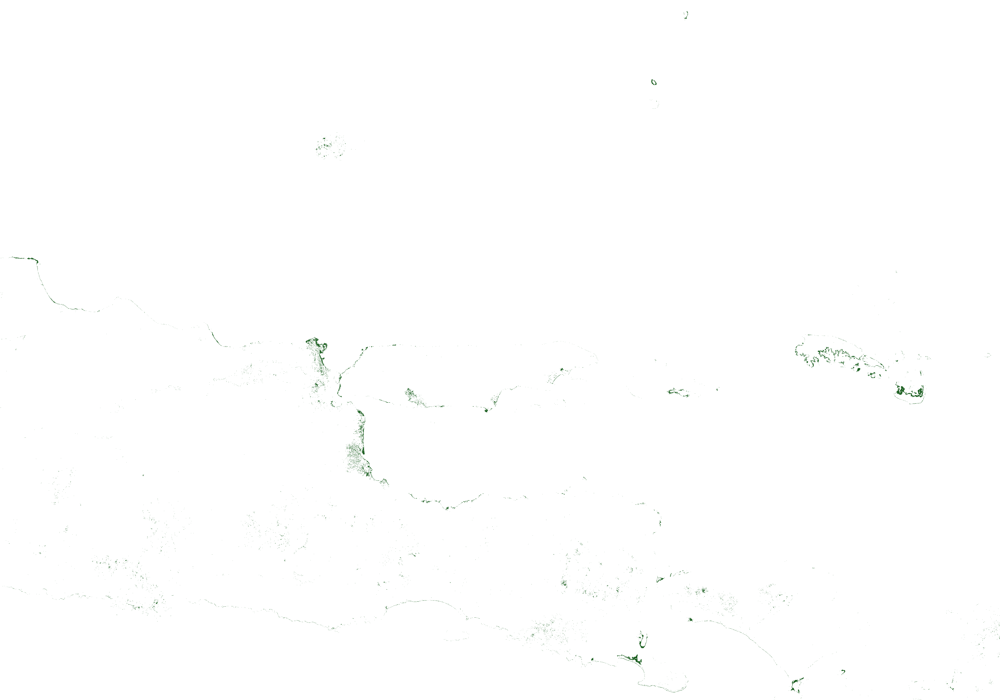
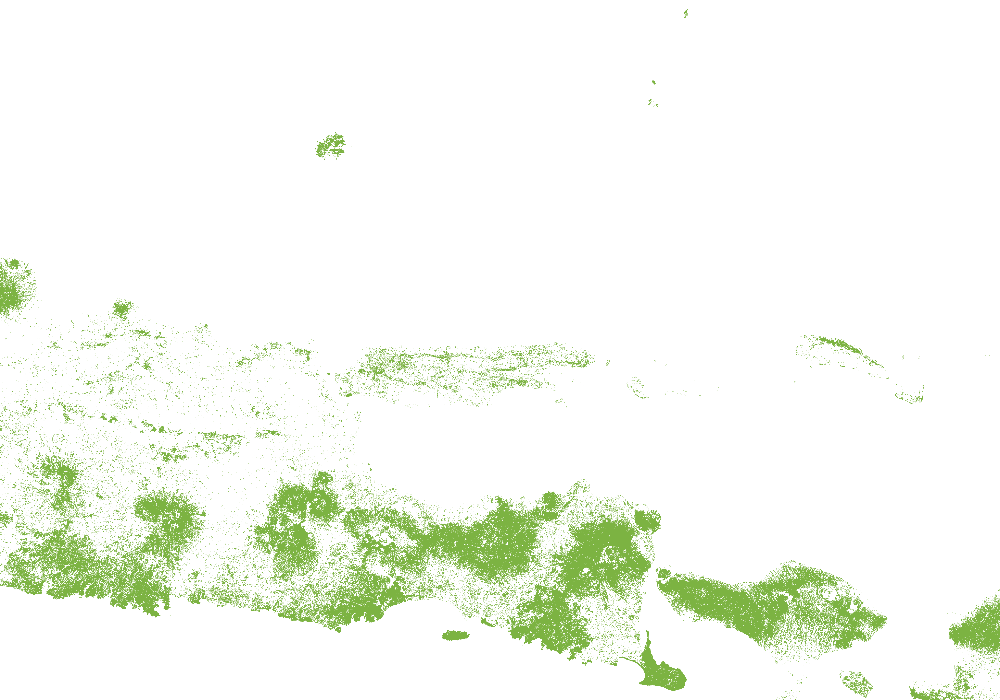
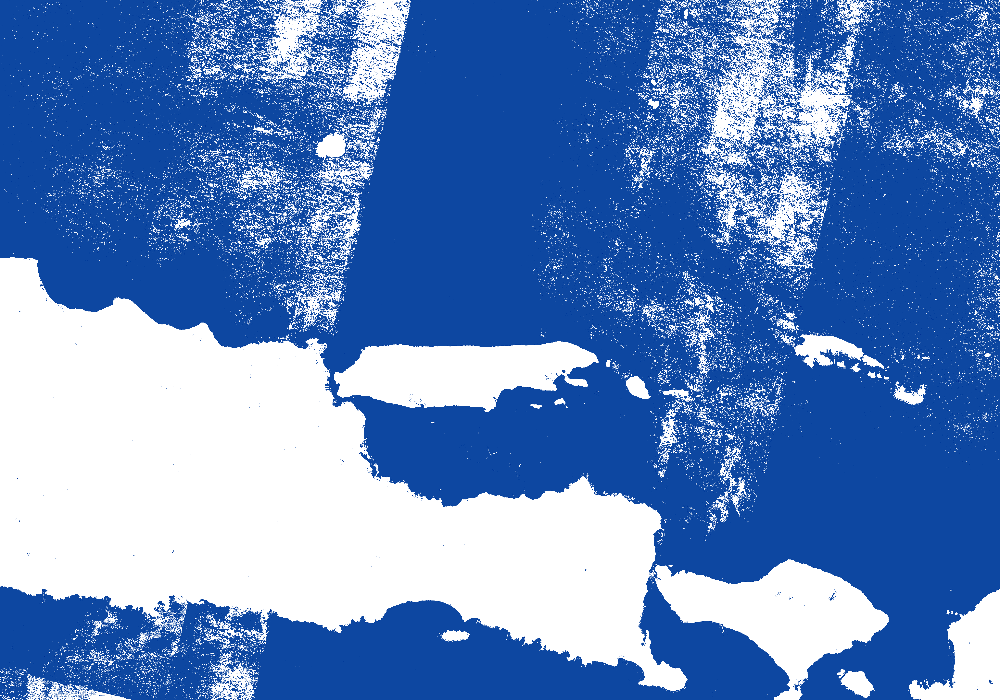
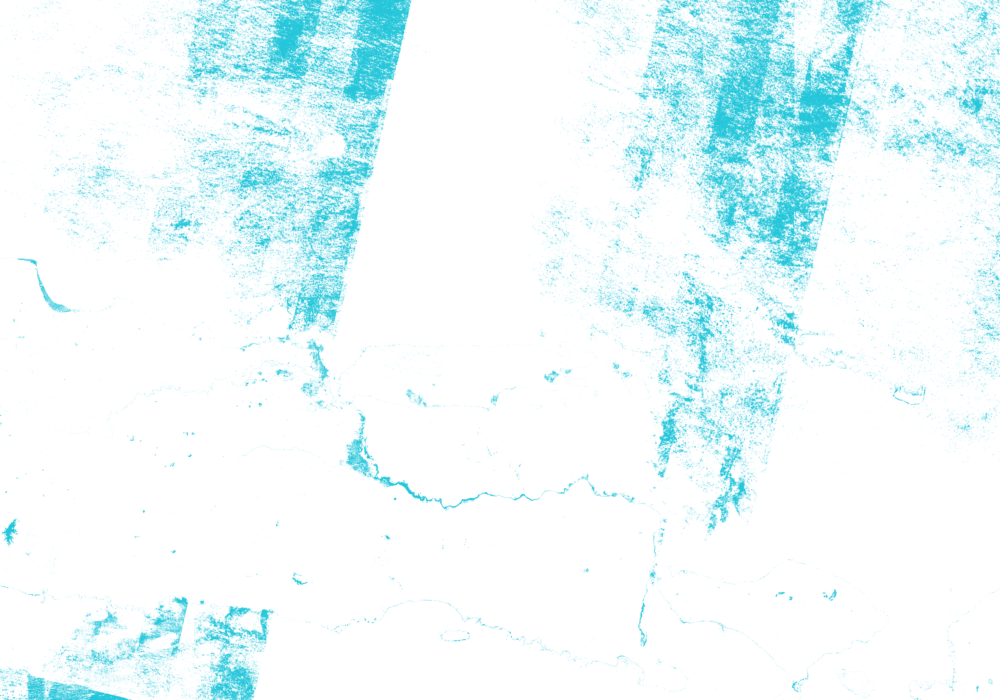

In [ ]:
import importlib
importlib.invalidate_caches()
from peta_util import buat_peta

peta = buat_peta(DATA_APP)
peta.save(DATA_APP / "peta.html")
peta

## 8. Kesimpulan dan Keterbatasan

### 8.1 Ringkasan Hasil

Angka berikut diambil langsung dari hasil eksekusi notebook, sehingga selalu sesuai dengan data dan pengaturan yang dipakai.

In [ ]:
# Ringkasan hasil (angka diambil langsung dari hasil eksekusi di atas)
print(f"Model terbaik     : {nama_terbaik}")
print(f"Akurasi data uji  : {acc:.3f}")
print(f"Cohen's Kappa     : {kappa:.3f}")
print(f"Kelas F1 terendah : {KELAS[terlemah][0]} ({laporan[KELAS[terlemah][0]]['f1-score']:.3f})")
print(f"Jumlah data       : {len(y_tr)} poligon latih, {len(y_te)} poligon uji, {len(KELAS)} kelas")
print(f"Periode citra     : {TANGGAL_MULAI} s.d. {TANGGAL_AKHIR}")
print()
ringkasan_luas = total_luas[["luas_ha", "persen"]].sort_values("luas_ha", ascending=False)
display(ringkasan_luas)
dominan = ringkasan_luas.index[0]
print(f"Kelas terluas di dalam batas Jawa Timur: {dominan} ({ringkasan_luas.loc[dominan, 'persen']:.1f}% dari piksel yang terklasifikasi)")

Model terbaik     : Random Forest
Akurasi data uji  : 0.944
Cohen's Kappa     : 0.933
Kelas F1 terendah : Lahan hijau (0.857)
Jumlah data       : 288 poligon latih, 72 poligon uji, 6 kelas
Periode citra     : 2025-10-18 s.d. 2026-10-17



,luas_ha,persen
kelas,,
Lahan hijau,1613291.5,33.44
Bangunan,1591110.8,32.98
Sawah,1533418.2,31.78
Danau,48257.9,1.00
Mangrove,35874.9,0.74
Laut,2862.1,0.06


Kelas terluas di dalam batas Jawa Timur: Lahan hijau (33.4% dari piksel yang terklasifikasi)


### 8.2 Deployment Streamlit

Link Website :
https://klasifikasi-jatim-lulc-25-26.streamlit.app/


### 8.3 Kesimpulan dan Keterbatasan

Notebook ini menggabungkan data poligon sampel, citra Sentinel-2, fitur spektral, tiga algoritma klasifikasi, evaluasi, dan penyajian hasil pada peta interaktif. Model terbaik ditentukan berdasarkan hasil validasi dan diperiksa kembali menggunakan data testing.

Beberapa hal yang perlu diperhatikan:
1. Setiap poligon diwakili satu titik, sehingga variasi tutupan di dalam poligon tidak seluruhnya tercakup.
2. Komposit median menggabungkan pengamatan dalam satu periode; perubahan fase pertumbuhan sawah dapat membuat kelas ini mirip dengan vegetasi lain.
3. Laut dan danau sama-sama berupa air sehingga keduanya masih berpotensi tertukar.
4. Resolusi peta 120 m tidak sesuai untuk mengidentifikasi objek kecil secara terperinci.
5. Estimasi luas dan label kelas merupakan keluaran model, bukan penetapan resmi penggunaan atau status lahan.
6. Interpretasi hasil sebaiknya mempertimbangkan kualitas sampel, cakupan tanggal citra, dan metrik evaluasi.